In [2]:
# Again Lets start with some imports...

from pathlib import Path

import geopandas as gpd
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

In [3]:
# Now to write paths to read in my data :)

Current_Path = Path.cwd()

Path_Root = Current_Path.parent.parent
Data_Path = Path_Root / "data" / "forecasting"
Forecast_Pop_File_Path = Data_Path / "SAP_Forecast_2136_Cleaned.csv"

Area_Path = Path_Root / "data" / "area_zones_data"
Area_File_Path = Area_Path / "Vic_Area_Zones.shp"

Forecast_Dwl_File_Path = Data_Path / "Household_Dwelling_Forecast_2136_CleanedV2.csv"


In [4]:
# Read in my data

Pop_Data = pd.read_csv(Forecast_Pop_File_Path)

Dwl_Data = pd.read_csv(Forecast_Dwl_File_Path)

Vic_Area_Zones = gpd.read_file(Area_File_Path)


In [5]:
# Now define the age groups

Age_Groups = [
    "0-4",
    "5-9",
    "10-14",
    "15-19",
    "20-24",
    "25-29",
    "30-34",
    "35-39",
    "40-44",
    "45-49",
    "50-54",
    "55-59",
    "60-64",
    "65-69",
    "70-74",
    "75-79",
    "80-84",
    "85+"
]

In [6]:
# Now to calc the total pop for each SA2 

Pop_Data["Population_2026"] = Pop_Data[
    [f"Persons_2026_{age}" for age in Age_Groups]
].sum(axis=1)

Pop_Data["Population_2036"] = Pop_Data[
    [f"Persons_2036_{age}" for age in Age_Groups]
].sum(axis=1)


In [7]:
# Now to calc pop growth for each SA2

Pop_Data["Population_Growth_Percent"] = (
    (
        Pop_Data["Population_2036"]
        - Pop_Data["Population_2026"]
    )
    / Pop_Data["Population_2026"]
) * 100

In [8]:
# Now to deal with a 2021 population of 0,

Pop_Data.loc[
    Pop_Data["Population_2026"] == 0,
    "Population_Growth_Percent"
] = np.nan

In [9]:
# Making sure types are the same

Pop_Data["SA2_Code"] = (
    Pop_Data["SA2_Code"]
    .astype(str)
    .str.strip()
)

Vic_Area_Zones["SA2_CODE21"] = (
    Vic_Area_Zones["SA2_CODE21"]
    .astype(str)
    .str.strip()
)


In [10]:
# Merging

Pop_Map = Vic_Area_Zones.merge(
    Pop_Data[
        [
            "SA2_Code",
            "Population_2026",
            "Population_2036",
            "Population_Growth_Percent"
        ]
    ],
    left_on="SA2_CODE21",
    right_on="SA2_Code",
    how="left"
)


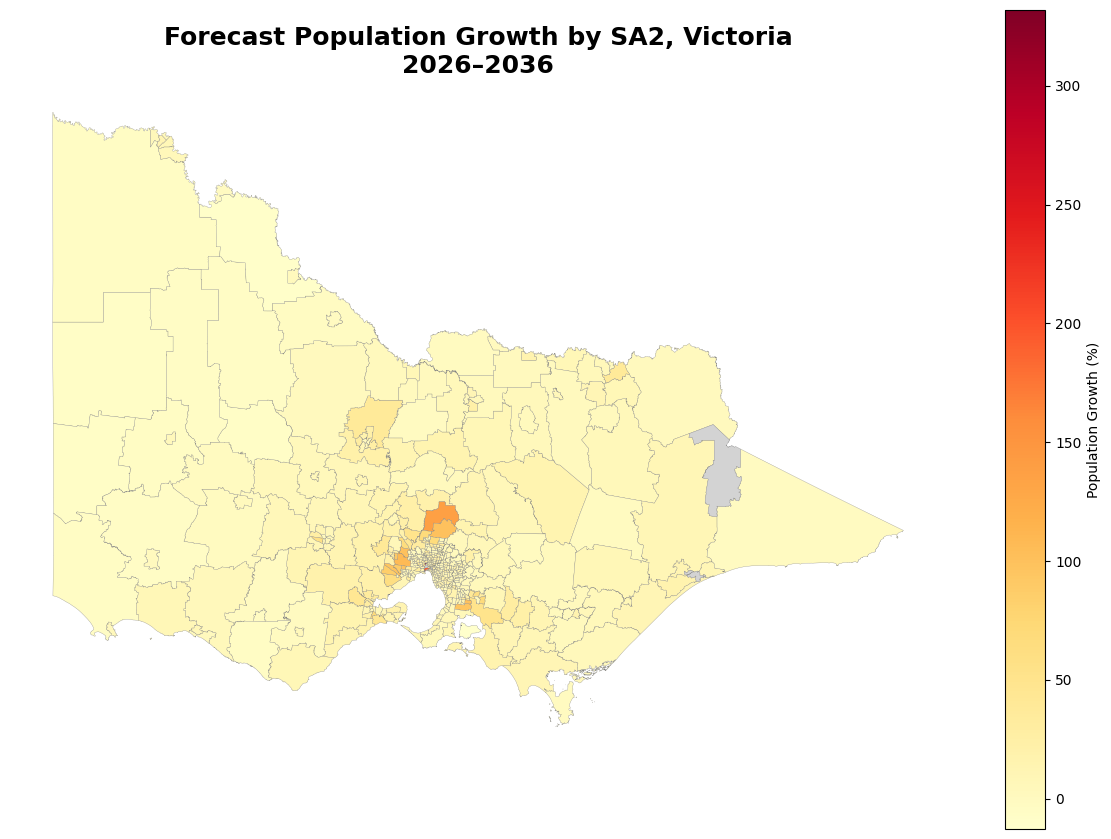

In [11]:
# Plotting

fig, ax = plt.subplots(
    figsize=(12, 12)
)

Pop_Map.plot(
    column="Population_Growth_Percent",
    cmap="YlOrRd",
    linewidth=0.2,
    edgecolor="grey",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Population Growth (%)",
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Forecast Population Growth by SA2, Victoria\n2026–2036",
    fontsize=18,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()
plt.show()

/var/folders/4d/nk4c_t511hx6c22d1xfb5p1w0000gn/T/ipykernel_8349/431164206.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar_ax.set_yticklabels(labels)


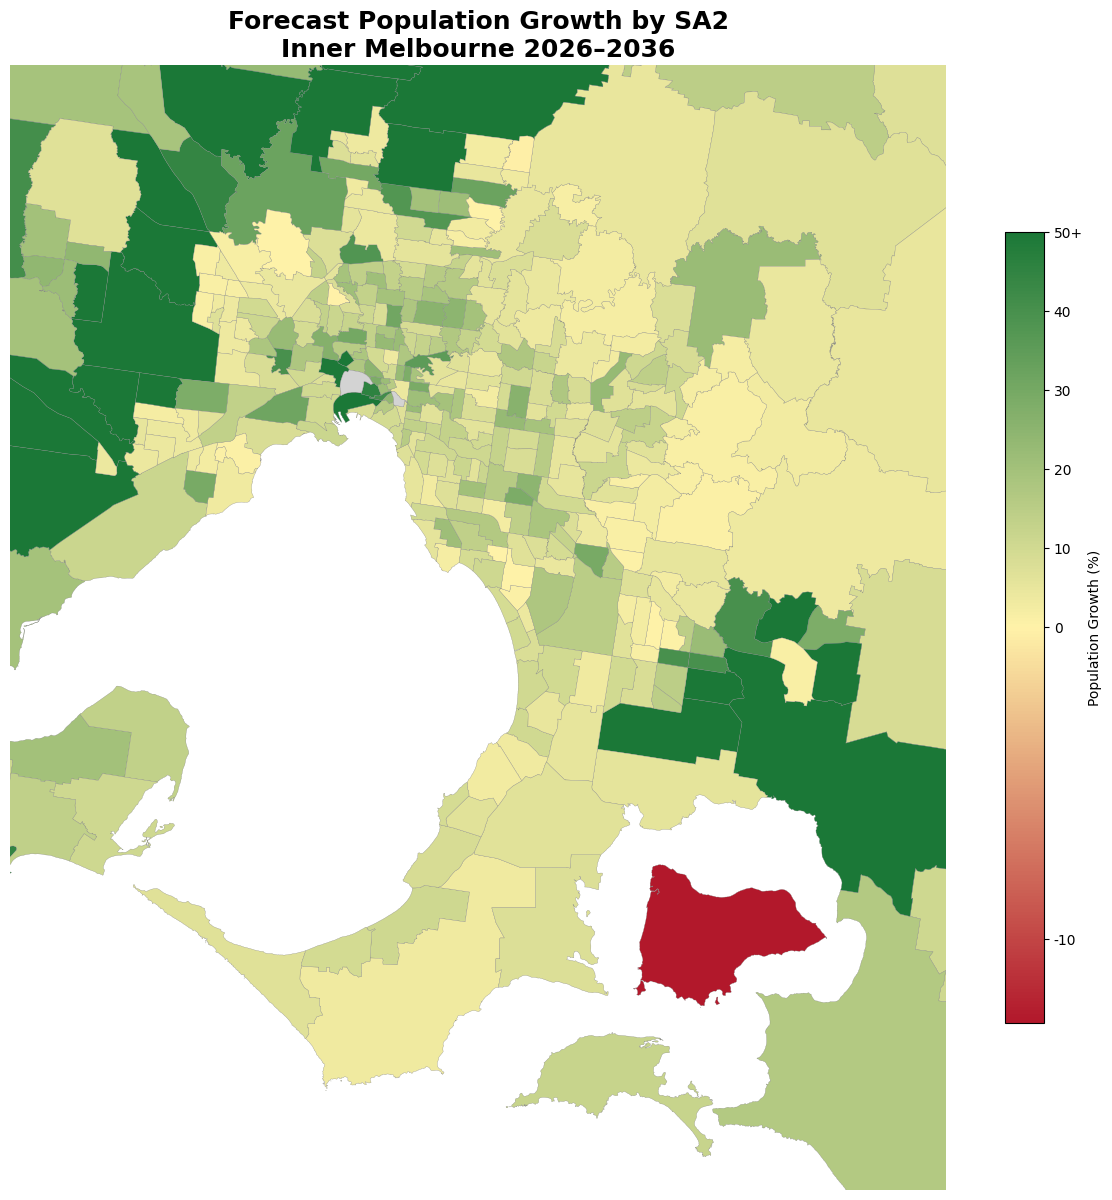

In [18]:
# Map time!!
# Create colour map

Red_Yellow_Green = LinearSegmentedColormap.from_list(
    "RedYellowGreen",
    [
        "#b2182b",   # Red = negative growth
        "#fff2a8",   # Yellow = around 0% growth
        "#1b7837"    # Green = positive growth
    ]
)

# Cap values at 50% for visualisation only

Pop_Map["Population_Growth_Plot"] = (
    Pop_Map["Population_Growth_Percent"]
    .clip(upper=50)
)

# Colour scale

min_growth = Pop_Map["Population_Growth_Percent"].min()

norm = TwoSlopeNorm(
    vmin=min_growth,
    vcenter=0,
    vmax=50
)

# Plot

fig, ax = plt.subplots(
    figsize=(12, 12)
)

Pop_Map.plot(
    column="Population_Growth_Plot",
    cmap=Red_Yellow_Green,
    norm=norm,
    linewidth=0.2,
    edgecolor="grey",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Population Growth (%)",
        "shrink": 0.7
    },
    ax=ax
)

# Fortmat the legend to show 50+ instead of 50

cbar_ax = fig.axes[-1]

ticks = cbar_ax.get_yticks()

labels = [
    "50+" if np.isclose(tick, 50) else f"{int(tick)}"
    for tick in ticks
]

cbar_ax.set_yticklabels(labels)

# Zoom into Inner Melbourne
ax.set_xlim(144.50, 145.65)
ax.set_ylim(-38.60, -37.50)


# Formatting


ax.set_title(
    "Forecast Population Growth by SA2\nInner Melbourne 2026–2036",
    fontsize=18,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()
plt.show()

/var/folders/4d/nk4c_t511hx6c22d1xfb5p1w0000gn/T/ipykernel_8349/1992600341.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar_ax.set_yticklabels(labels)


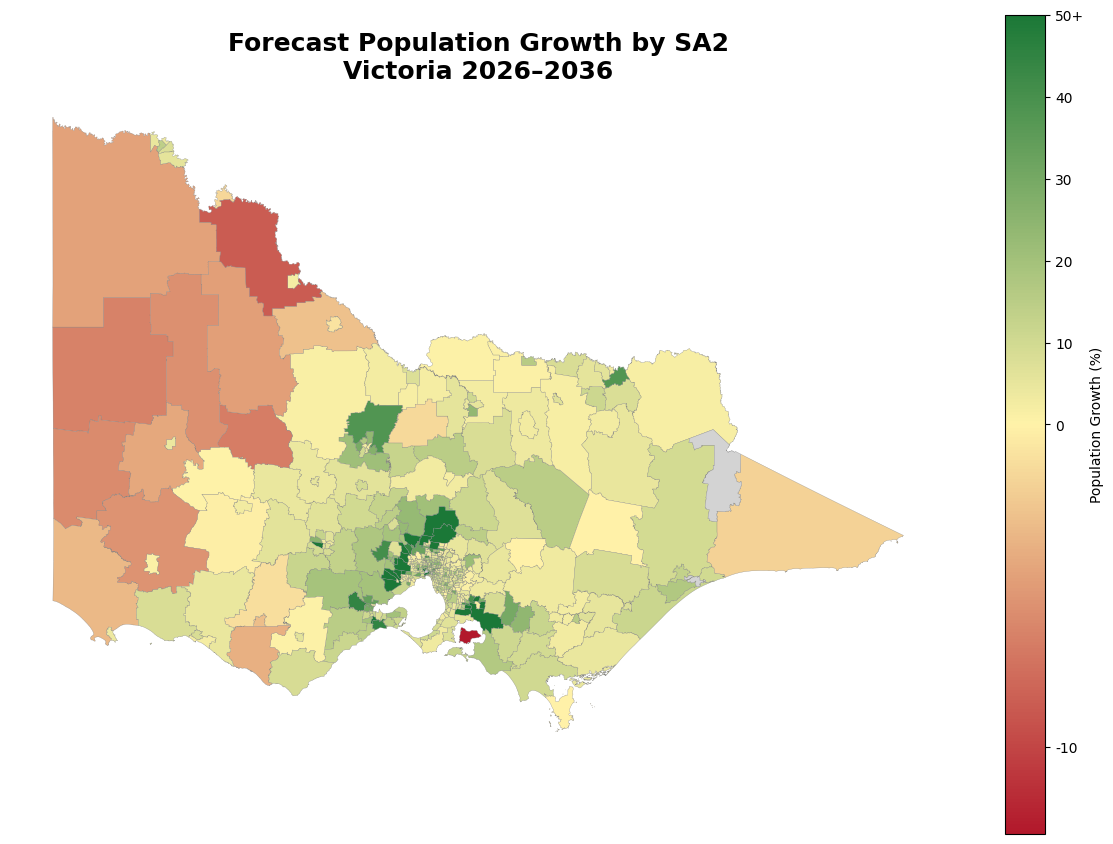

In [19]:
# Map time!!
# Create colour map

Red_Yellow_Green = LinearSegmentedColormap.from_list(
    "RedYellowGreen",
    [
        "#b2182b",   # Red = negative growth
        "#fff2a8",   # Yellow = around 0% growth
        "#1b7837"    # Green = positive growth
    ]
)

# Cap values at 50% for visualisation only

Pop_Map["Population_Growth_Plot"] = (
    Pop_Map["Population_Growth_Percent"]
    .clip(upper=50)
)

# Colour scale

min_growth = Pop_Map["Population_Growth_Percent"].min()

norm = TwoSlopeNorm(
    vmin=min_growth,
    vcenter=0,
    vmax=50
)

# Plot

fig, ax = plt.subplots(
    figsize=(12, 12)
)

Pop_Map.plot(
    column="Population_Growth_Plot",
    cmap=Red_Yellow_Green,
    norm=norm,
    linewidth=0.2,
    edgecolor="grey",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Population Growth (%)",
        "shrink": 0.7
    },
    ax=ax
)

# Fortmat the legend to show 50+ instead of 50

cbar_ax = fig.axes[-1]

ticks = cbar_ax.get_yticks()

labels = [
    "50+" if np.isclose(tick, 50) else f"{int(tick)}"
    for tick in ticks
]

cbar_ax.set_yticklabels(labels)


# Formatting


ax.set_title(
    "Forecast Population Growth by SA2\nVictoria 2026–2036",
    fontsize=18,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
Pop_Map["Population_Growth_Percent"].describe()

count    518.000000
mean      14.438672
std       23.748506
min      -12.681872
25%        4.132285
50%        8.672123
75%       16.263340
max      331.844821
Name: Population_Growth_Percent, dtype: float64

In [15]:
Pop_Map[
    [
        "SA2_NAME21",
        "Population_2026",
        "Population_2036",
        "Population_Growth_Percent"
    ]
].sort_values(
    "Population_Growth_Percent",
    ascending=False
).head(50)

,SA2_NAME21,Population_2026,Population_2036,Population_Growth_Percent
130,Flemington Racecourse,527.930995,2279.842663,331.844821
147,Port Melbourne Industrial,12184.403341,35877.149503,194.451427
246,Wallan,37122.406655,87870.773574,136.705487
422,Rockbank - Mount Cottrell,41465.331586,85980.885250,107.356078
247,Whittlesea,22795.969436,45658.473848,100.291872
364,Clyde North - South,31586.685877,63240.936145,100.213901
430,Fraser Rise - Plumpton,26192.968124,52290.420413,99.635338
448,Tarneit - North,19692.313304,38690.734277,96.476329
453,Wyndham Vale - North,16848.854364,33087.395559,96.377717
357,Cranbourne South,32306.373727,62789.611795,94.356731


In [16]:
print(Pop_Map.crs)

GEOGCS["GCS_GDA2020",DATUM["Geocentric_Datum_of_Australia_2020",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1168"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433],AXIS["Longitude",EAST],AXIS["Latitude",NORTH]]
